# Phase 4 -- AC sweep analysis

Reads `ac_budget_sweep_results.csv` (produced by `benchmarks_ac_budget_sweep.py`) and produces the two project deliverables:

- **Peak memory consumption vs mini-batch size** -- bar chart, w/ and w/o AC
- **Iteration latency vs mini-batch size** -- line chart, w/ and w/o AC

The CSV contains one row per `(model, batch_size, budget_fraction)` cell. `config = baseline` means AC is off; `config = ac_<frac>` means AC is on with the given budget fraction.

Edit `BUDGETS_TO_PLOT` below to choose which AC budgets to compare against the baseline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_PATH = "/Users/zhaochong/Desktop/mlsys-project/ac_budget_artifacts/ac_budget_sweep_results.csv"
BUDGETS_TO_PLOT = [0.5, 0.6, 0.7, 0.8,0.9]    # which AC budgets to overlay on the plots

df = pd.read_csv(CSV_PATH)
df.head()
print(df.groupby(["model", "config"])["batch_size"].apply(list))

model      config  
Bert       ac_0.50       [2, 4, 8, 16, 32, 64]
           ac_0.60       [2, 4, 8, 16, 32, 64]
           ac_0.70       [2, 4, 8, 16, 32, 64]
           ac_0.80       [2, 4, 8, 16, 32, 64]
           ac_0.90       [2, 4, 8, 16, 32, 64]
           baseline      [2, 4, 8, 16, 32, 64]
Resnet152  ac_0.50        [8, 16, 32, 64, 128]
           ac_0.60        [8, 16, 32, 64, 128]
           ac_0.70     [4, 8, 16, 32, 64, 128]
           ac_0.80     [4, 8, 16, 32, 64, 128]
           ac_0.90     [4, 8, 16, 32, 64, 128]
           baseline    [4, 8, 16, 32, 64, 128]
Name: batch_size, dtype: object


## Plot 1 -- Peak memory vs mini-batch size

One line per config (baseline + each chosen AC budget). We use `peak_post_ac_MB` (the simulator's predicted fwd+bwd peak) since that's what the AC algorithm targets. 

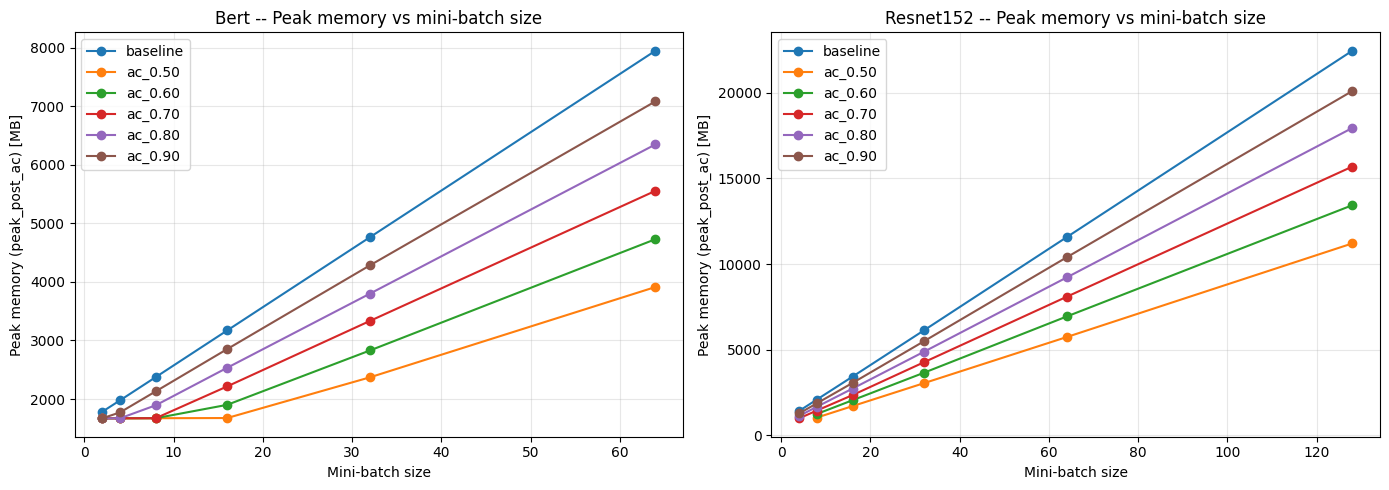

In [11]:
MEMORY_COL = "peak_post_ac_MB"   # or "posthoc_peak_MB"

configs = ["baseline"] + [f"ac_{b:.2f}" for b in BUDGETS_TO_PLOT]
models  = sorted(df["model"].unique())

fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=False)
if len(models) == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    sub = df[df["model"] == model]
    batch_sizes = sorted(sub["batch_size"].unique())

    for cfg in configs:
        cfg_rows = sub[sub["config"] == cfg].set_index("batch_size")
        ys = [cfg_rows[MEMORY_COL].get(bs, np.nan) for bs in batch_sizes]
        ax.plot(batch_sizes, ys, marker="o", label=cfg)

    ax.set_xlabel("Mini-batch size")
    ax.set_ylabel(f"Peak memory ({MEMORY_COL.replace('_MB', '')}) [MB]")
    ax.set_title(f"{model} -- Peak memory vs mini-batch size")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ac_sweep_peak_memory.png", dpi=150, bbox_inches="tight")
plt.show()


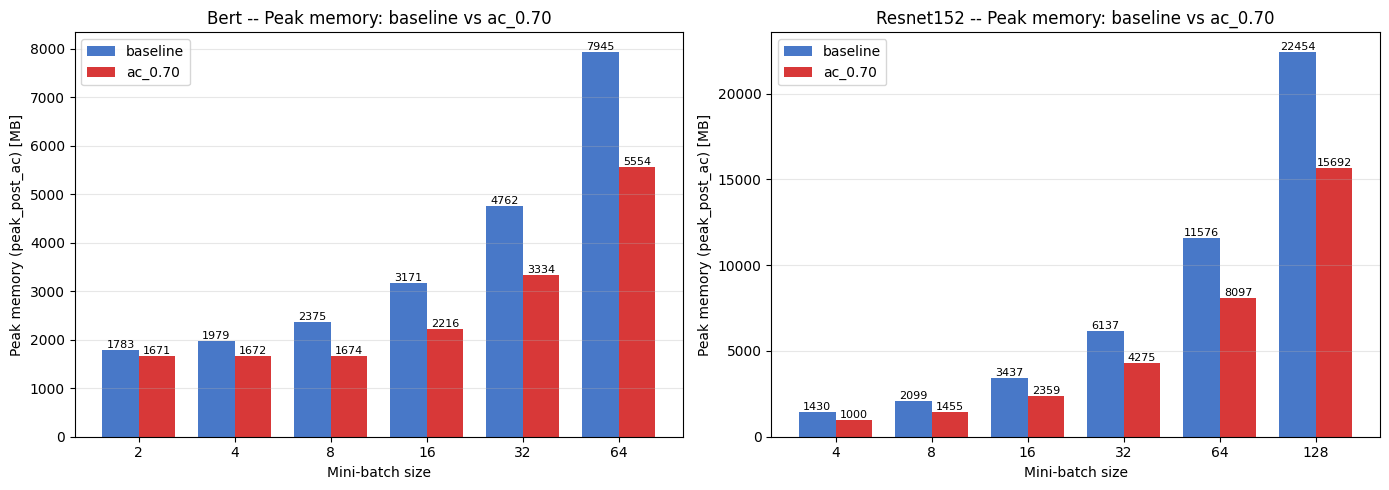

In [12]:
BAR_CONFIGS = ["baseline", "ac_0.70"]
BAR_COLORS  = {"baseline": "#4878c8", "ac_0.70": "#d83838"}

fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=False)
if len(models) == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    sub = df[df["model"] == model]
    batch_sizes = sorted(sub["batch_size"].unique())

    x = np.arange(len(batch_sizes))
    width = 0.38

    for i, cfg in enumerate(BAR_CONFIGS):
        cfg_rows = sub[sub["config"] == cfg].set_index("batch_size")
        ys = [cfg_rows[MEMORY_COL].get(bs, np.nan) for bs in batch_sizes]
        offset = (i - (len(BAR_CONFIGS) - 1) / 2) * width
        bars = ax.bar(x + offset, ys, width, label=cfg, color=BAR_COLORS.get(cfg))
        for rect, val in zip(bars, ys):
            if not np.isnan(val):
                ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height(),
                        f"{val:.0f}", ha="center", va="bottom", fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(batch_sizes)
    ax.set_xlabel("Mini-batch size")
    ax.set_ylabel(f"Peak memory ({MEMORY_COL.replace('_MB', '')}) [MB]")
    ax.set_title(f"{model} -- Peak memory: baseline vs ac_0.70")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("ac_sweep_peak_memory_bar.png", dpi=150, bbox_inches="tight")
plt.show()


### Interpretation -- Peak memory
For ResNet-152, activation checkpointing behaves almost exactly as expected. All AC curves stay below the baseline, and the ordering is consistent: more aggressive AC fractions produce lower peak memory. As mini-batch size increases, the absolute memory saving also increases, because activation memory scales with batch size while much of the non-activation memory remains relatively fixed. This shows a clean memory–compute trade-off: ResNet-152 has enough batch-dependent activation memory for checkpointing to reduce peak memory proportionally.

BERT shows a different pattern. For mild AC settings such as ac_0.90 and ac_0.80, the curves behave normally and remain below the baseline. However, for more aggressive settings such as ac_0.70, ac_0.60, and especially ac_0.50, the small-batch region becomes nearly flat. This means that different batch sizes can end up with similar post-AC peak memory, not because their baselines are similar, but because the checkpointed run is hitting an effective lower bound.

The reason is that small-batch BERT has limited activation headroom. Its peak memory contains a large fixed component, mainly parameters and optimizer states, plus some live gradients and other non-recomputable tensors. Activation checkpointing can only reduce saved activation tensors; it cannot reduce those fixed components. Therefore, when the AC target is too aggressive, the planner cannot push memory down proportionally to the requested fraction. The result is that bs=16 and bs=32 under ac_0.50 can land near the same peak memory because both are bounded by the same effective floor rather than by their original baseline peaks.

This also suggests that BERT’s small-batch behavior is not simply “AC failing,” but a regime where AC has much less useful memory to operate on. The issue is further amplified if the profiler overestimates the memory benefit of view-like operations such as view, transpose, and getitem, which may share storage with their inputs and therefore may not release as much real memory as their logical tensor size suggests


**BERT**: small batches (bs=2/4/8/16) collapse to a flat plateau at ~1670 MB regardless of budget:

| batch | baseline peak | `ac_0.5` peak | n_recomputed |
|-------|--------------|---------------|--------------|
| bs=2  | 1783 MB | **1671 MB** | 362 (all picked) |
| bs=4  | 1979 MB | **1672 MB** | 362 (all picked) |
| bs=8  | 2375 MB | **1674 MB** | 362 (all picked) |
| bs=16 | 3170 MB | **1677 MB** | 362 (all picked) |
| bs=32 | 4762 MB | 2371 MB | 179 (normal) |
| bs=64 | 7945 MB | 3913 MB | 167 (normal) |

Breakdown at the fwd+bwd peak step:

- `params (438 MB)` + `opt_states / Adam m+v (876 MB)` = **1314 MB always alive** -- AC cannot touch any of this
- + ~350 MB of residual transient activations (at any backward step at least one activation must be live -- being consumed or just recomputed -- so AC cannot drive activation memory to zero)
- = **~1670 MB hard floor**

Available activation budget for AC to work with: `peak - floor = 1870 - 1314 = ~556 MB`. When `ac_0.5` asks for `0.5 x 1783 = 891 MB` total peak (i.e. negative activation budget), the target is mathematically unreachable. Phase 2's greedy loop never converges and exhausts the entire 362-candidate list. By bs=32 the `ac_0.5` budget (`0.5 x 4762 = 2381 MB`) finally clears the 1670 MB floor, only 179 picks are needed, and the algorithm behaves normally.


## Plot 2 -- Iteration latency overhead vs baseline (line)

For each `(model, batch_size)`, compute `latency_overhead_pct = (ac_latency / baseline_latency - 1) * 100` so the y-axis directly answers "how much more latency does AC cost?". The dashed 0% line is the baseline; everything above it is the AC tax. This view normalizes away batch-size scaling, making the trade-off curves comparable across batch sizes.


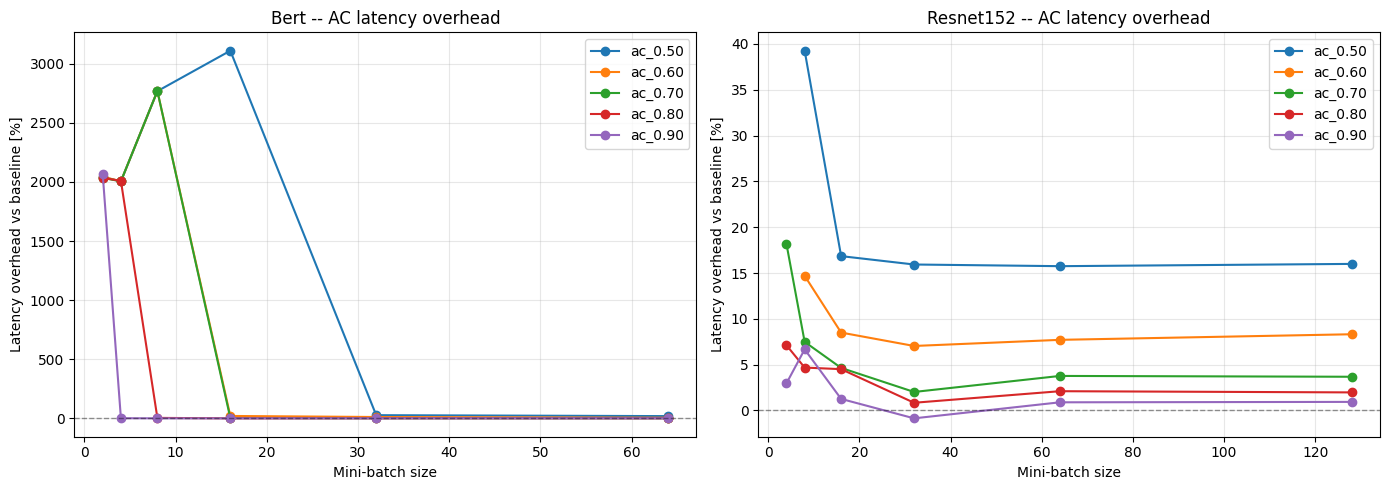


Latency overhead % (NaN = cell missing or OOM):
config                ac_0.50  ac_0.60  ac_0.70  ac_0.80  ac_0.90  baseline
model     batch_size                                                       
Bert      2            2042.1   2044.5   2034.7   2034.7   2071.2       0.0
          4            2005.6   2005.7   2005.5   2009.5      1.1       0.0
          8            2768.4   2768.9   2769.5      3.9      0.2       0.0
          16           3110.6     20.3      2.8      0.3      0.1       0.0
          32             26.8     11.4      1.2      0.6      0.3       0.0
          64             18.9      5.5      1.0      0.5      0.4       0.0
Resnet152 4               NaN      NaN     18.2      7.1      3.0       0.0
          8              39.3     14.7      7.5      4.7      6.7       0.0
          16             16.8      8.5      4.6      4.5      1.3       0.0
          32             15.9      7.0      2.0      0.8     -0.9       0.0
          64             15.7      7.7 

In [ ]:
baseline_lat = (
    df[df["config"] == "baseline"]
    .set_index(["model", "batch_size"])["latency_median_ms"]
)

def _overhead_pct(row):
    base = baseline_lat.get((row["model"], row["batch_size"]), np.nan)
    if np.isnan(base) or base == 0 or np.isnan(row["latency_median_ms"]):
        return np.nan
    return (row["latency_median_ms"] / base - 1.0) * 100.0

df["latency_overhead_pct"] = df.apply(_overhead_pct, axis=1)

# AC-only configs (baseline is 0% by definition; we draw it as a reference line).
ac_configs = [c for c in configs if c != "baseline"]

fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=False)
if len(models) == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    sub = df[df["model"] == model]
    batch_sizes = sorted(sub["batch_size"].unique())

    for cfg in ac_configs:
        cfg_rows = sub[sub["config"] == cfg].set_index("batch_size")
        ys = [cfg_rows["latency_overhead_pct"].get(bs, np.nan) for bs in batch_sizes]
        ax.plot(batch_sizes, ys, marker="o", label=cfg)

    ax.axhline(0, color="black", linestyle="--", alpha=0.4, linewidth=1)
    ax.set_xlabel("Mini-batch size")
    ax.set_ylabel("Latency overhead vs baseline [%]")
    ax.set_title(f"{model} -- AC latency overhead")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ac_sweep_latency_overhead.png", dpi=150, bbox_inches="tight")
plt.show()

# Also print the table so the spikes have concrete numbers attached.
print("\nLatency overhead % (NaN = cell missing or OOM):")
pivot = (
    df.pivot_table(
        index=["model", "batch_size"],
        columns="config",
        values="latency_overhead_pct",
        aggfunc="first",
    )
    .round(1)
)
print(pivot.to_string())


For small-batch BERT, aggressive AC budgets such as ac_0.50–0.70 produce pathological overheads of 20×–30×. 

This occurs because the planner selects nearly all recomputable candidates while trying to satisfy an overly aggressive memory target. 

During backward, Phase 3 inserts many independent recomputation subgraphs, so shared upstream computations are repeatedly recomputed instead of being reused. 

The cost is further amplified at small batch sizes, where GPU execution is dominated by kernel launch overhead. Once the batch size becomes large enough, or the AC budget becomes less aggressive, the planner selects a smaller useful subset and the latency overhead returns to a normal range. 

Thus, the latency spike is the compute-side consequence of the same low-headroom regime that caused the flat post-AC memory curves.



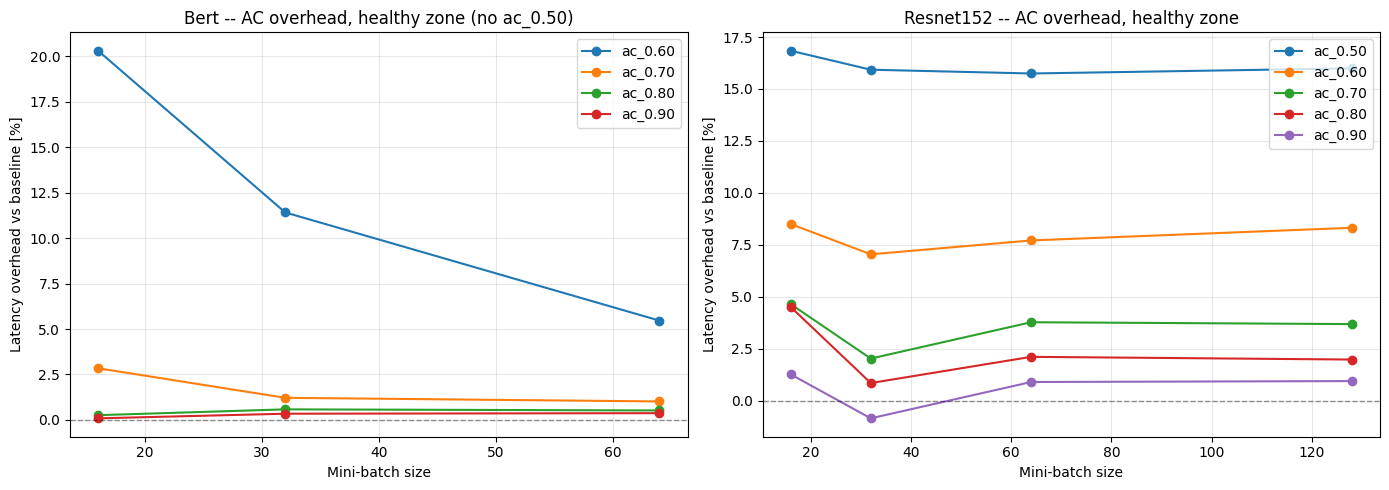

In [ ]:
# AC overhead, healthy zone only.

HEALTHY_FILTER = {
    "Bert":      {"min_bs": 16, "skip_configs": {"ac_0.50"}},
    "Resnet152": {"min_bs": 16,  "skip_configs": set()},
}

fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=False)
if len(models) == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    rule = HEALTHY_FILTER.get(model, {"min_bs": 0, "skip_configs": set()})
    sub = df[(df["model"] == model) & (df["batch_size"] >= rule["min_bs"])]
    batch_sizes = sorted(sub["batch_size"].unique())

    for cfg in ac_configs:
        if cfg in rule["skip_configs"]:
            continue
        cfg_rows = sub[sub["config"] == cfg].set_index("batch_size")
        if cfg_rows.empty:
            continue
        ys = [cfg_rows["latency_overhead_pct"].get(bs, np.nan) for bs in batch_sizes]
        ax.plot(batch_sizes, ys, marker="o", label=cfg)

    ax.axhline(0, color="black", linestyle="--", alpha=0.4, linewidth=1)
    ax.set_xlabel("Mini-batch size")
    ax.set_ylabel("Latency overhead vs baseline [%]")
    skip = sorted(rule["skip_configs"])
    suffix = f" (no {', '.join(skip)})" if skip else ""
    ax.set_title(f"{model} -- AC overhead, healthy zone{suffix}")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ac_sweep_latency_overhead_healthy.png", dpi=150, bbox_inches="tight")
plt.show()


**ResNet-152**: clean monotone trade-off. `ac_0.9` adds ~1-3%, `ac_0.7` ~2-8%, `ac_0.5` ~16-39%. The relative overhead is approximately batch-size-invariant for `bs >= 8` because both forward compute and recomputation overhead scale at the same rate. At bs=128, `ac_0.5` adds only ~16% latency for a ~50% memory saving.

In ResNet-152, most checkpointed tensors come from convolutional layers. Both the original forward/backward pass and the recomputation pass are dominated by the same convolution operations. Since convolution cost scales roughly linearly with batch size, increasing the batch size increases both the baseline runtime and the recomputation runtime at a similar rate. As a result, the absolute overhead grows with batch size, but the relative overhead remains roughly stable.

**BERT**: The healthy zone (bs=32, bs=64) shows the same character as ResNet-152 -- `ac_0.5` adds ~19-27%, `ac_0.7` adds ~1-2%.

**Takeaway**: when the budget is reachable (`budget > floor`), `ac_0.5` costs roughly 16-28% latency on both models -- exactly the trade-off μ-TWO predicts. 

When the budget is unreachable, the percentage view dramatizes the failure mode in a way the absolute-ms view obscured. 

## Recomputed-activation summary (healthy zone only)

This summary aggregates **only the healthy cells**.
- **ResNet-152**: `bs >= 8`, all budgets -- 25 cells, 1489 total picks, avg 60 picks/cell
- **BERT**: `bs >= 16`, exclude `ac_0.50` -- 12 cells, 1072 total picks, avg 89 picks/cell

> *Terminology note*: in this project an **"activation"** means any **intermediate tensor produced in the forward pass and consumed in the backward pass** . A `view`, a `transpose`, or even a `getitem` is an "activation" in this AC sense as long as it crosses the fwd/bwd boundary.

### Op-kind composition of Phase 2's picks

| Op kind | ResNet-152 (% of picks) | BERT (% of picks) | 
|---------|-------------------------|-------------------|
| `convolution` | **80.3%** (1196 picks) | 0% |
| `relu` | 16.8% (250 picks) | 0% |
| `view` | 0% | **49.5%** (531 picks) | 
| `t` | 1.1% (16 picks) | **46.2%** (495 picks) | 
| `getitem` | 1.8% (27 picks) | 4.0% (43 picks) | 
| `add` | 0% | 0.3% (3 picks) | 


### Where the BERT view-bias originates

The cause-and-effect is straightforward and lies entirely **upstream of Phase 2**:

1. **Phase 1 (profiler)** treats every node whose output crosses the fwd/bwd boundary as an "activation", including views, transposes, and getitems. This is correct per the project's definition of "activation" (any intermediate tensor consumed in backward).

2. **`graph_prof.py::_tensor_bytes`** computes each activation's size as `numel * element_size`.

### What this means for the measured numbers

| BERT cell | simulator predicted | `posthoc_peak_MB` measured |
|-----------|--------------------|----------------------------|
| bs=2 baseline -> ac_0.5 | 1783 -> 1671 | 3358 -> **3367 (no save)** |
| bs=8 baseline -> ac_0.5 | 2375 -> 1674 | 3376 -> **3393 (slightly worse)** |
| bs=16 baseline -> ac_0.5 | 3170 -> 1677 | 3362 -> **3413 (slightly worse)** |
| bs=32 baseline -> ac_0.5 | 4762 -> 2371 | 3752 -> **3425 (~9% save)** |
| bs=64 baseline -> ac_0.5 | 7945 -> 3913 | 6226 -> **3409 (~45% save)** |

Two things stand out:

- **At small batches (bs <= 16) the actual peak does not drop, and sometimes slightly increases**. 
- **At large batches (bs = 32, 64) the actual peak does drop substantially**. Here the recomputation chains for the picked views walk back through real intermediate ops (matmul outputs, layernorms) all the way to placeholders, and Phase 3's rewriting genuinely shortens the lifetimes of those real parent tensors. 

So AC does provide real memory benefit on BERT at larger batch sizes, but the credit belongs to the *parent tensors* that get incidentally recomputed when their view children are picked -- not to the views themselves. 

### Suggested fix?

```python
PURE_VIEW_OPS = {
    torch.ops.aten.view.default,
    torch.ops.aten.transpose.int,
    torch.ops.aten.t.default,
    torch.ops.aten.expand.default,
    torch.ops.aten.select.int,
    torch.ops.aten.slice.Tensor,
    # operator.getitem is FX-level, handled separately
}

@staticmethod
def _tensor_bytes(n, result):
    if n is not None and n.target in PURE_VIEW_OPS:
        return 0    # alias: no incremental allocation
    if isinstance(result, torch.Tensor):
        return result.numel() * result.element_size()
    if isinstance(result, (tuple, list)):
        return sum(GraphProfiler._tensor_bytes(None, r) for r in result)
    return 0
```
